Dataset Shape: (6964, 27)

Using activity column: 'activity_name'

Top 10 Activities by Frequency:
activity_name
Triage                  1235
Registration            1000
Doctor Assessment       1000
Discharge               1000
X-Ray                    584
Radiology Result         584
Documentation Review     584
Lab Collection           371
Lab Result               371
Doctor Reassessment      235
Name: count, dtype: int64


C:\Users\HP\AppData\Local\Temp\ipykernel_8656\3953217214.py:35: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=activity_counts.values[:10], y=activity_counts.index[:10], palette="mako")


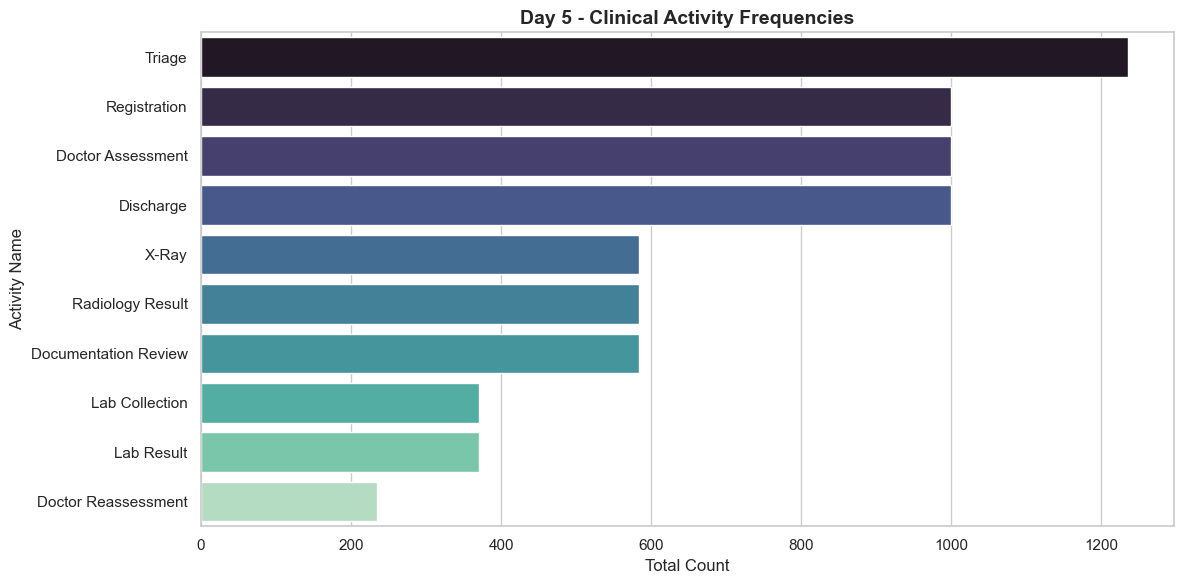

In [1]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Set style
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 6)

# Load Scaled Events Dataset from processed_new folder
data_path = os.path.join("..", "data", "processed_new", "careflow_events_scaled.csv")
if not os.path.exists(data_path):
    data_path = os.path.join("data", "processed_new", "careflow_events_scaled.csv")

df = pd.read_csv(data_path)
print("Dataset Shape:", df.shape)

# Identify activity column dynamically
activity_col = None
for col in ["activity_name", "activity", "Activity", "event", "department", "concept:name"]:
    if col in df.columns:
        activity_col = col
        break

if activity_col:
    print(f"\nUsing activity column: '{activity_col}'")
    
    # 1. Activity Frequency Count
    activity_counts = df[activity_col].value_counts()
    print("\nTop 10 Activities by Frequency:")
    print(activity_counts.head(10))
    
    # 2. Plotting Activity Frequencies
    plt.figure(figsize=(12, 6))
    sns.barplot(x=activity_counts.values[:10], y=activity_counts.index[:10], palette="mako")
    plt.title("Day 5 - Clinical Activity Frequencies", fontsize=14, fontweight="bold")
    plt.xlabel("Total Count", fontsize=12)
    plt.ylabel("Activity Name", fontsize=12)
    plt.tight_layout()
    plt.show()
else:
    print("Activity column not found. Available columns:", df.columns.tolist())